In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/maheshmaaruthi/pishing-websites-dataset/phishing+websites/Phishing Websites Features.docx
/kaggle/input/datasets/maheshmaaruthi/pishing-websites-dataset/phishing+websites/Training Dataset.arff
/kaggle/input/datasets/maheshmaaruthi/pishing-websites-dataset/phishing+websites/.old.arff


In [2]:
from scipy.io import arff
import pandas as pd
data,meta =arff.loadarff("/kaggle/input/datasets/maheshmaaruthi/pishing-websites-dataset/phishing+websites/Training Dataset.arff")
df=pd.DataFrame(data)
df = df.map(lambda x: x.decode("utf-8") if isinstance(x, bytes) else x)
df = df.astype(int)
from IPython.display import display
display(df.head())
display(df.tail())
print(df.columns)

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
11050,1,-1,1,-1,1,1,1,1,-1,-1,...,-1,-1,1,1,-1,-1,1,1,1,1
11051,-1,1,1,-1,-1,-1,1,-1,-1,-1,...,-1,1,1,1,1,1,1,-1,1,-1
11052,1,-1,1,1,1,-1,1,-1,-1,1,...,1,1,1,1,1,-1,1,0,1,-1
11053,-1,-1,1,1,1,-1,-1,-1,1,-1,...,-1,1,1,1,1,-1,1,1,1,-1
11054,-1,-1,1,1,1,-1,-1,-1,1,1,...,1,1,-1,1,-1,-1,-1,1,-1,-1


Index(['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor',
       'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL',
       'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe',
       'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank',
       'Google_Index', 'Links_pointing_to_page', 'Statistical_report',
       'Result'],
      dtype='object')


In [3]:
print(df.info())
print(df.describe())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   having_IP_Address            11055 non-null  int64
 1   URL_Length                   11055 non-null  int64
 2   Shortining_Service           11055 non-null  int64
 3   having_At_Symbol             11055 non-null  int64
 4   double_slash_redirecting     11055 non-null  int64
 5   Prefix_Suffix                11055 non-null  int64
 6   having_Sub_Domain            11055 non-null  int64
 7   SSLfinal_State               11055 non-null  int64
 8   Domain_registeration_length  11055 non-null  int64
 9   Favicon                      11055 non-null  int64
 10  port                         11055 non-null  int64
 11  HTTPS_token                  11055 non-null  int64
 12  Request_URL                  11055 non-null  int64
 13  URL_of_Anchor                11055 non-null  i

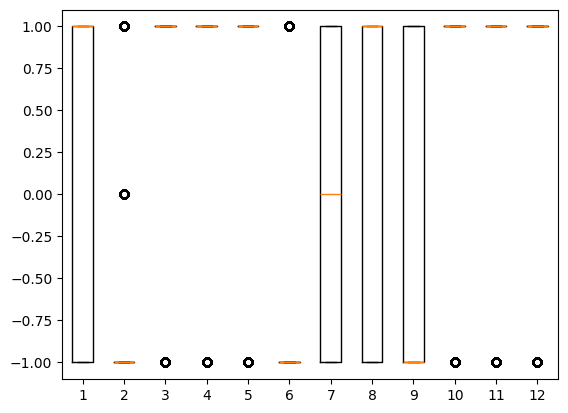

In [4]:
import matplotlib.pyplot as plt

plt.boxplot(df[['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token']])
plt.show()

In [5]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
x=(df[['having_IP_Address', 'URL_Length', 'Shortining_Service',
       'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix',
       'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length',
       'Favicon', 'port', 'HTTPS_token']])
y=(df['Result'])
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
model=SVC(kernel="rbf",C=1)
model.fit(x_train,y_train)
prediction=model.predict(x_test)
print(prediction)
accuracy=accuracy_score(y_test,prediction)
print(accuracy)



[-1 -1 -1 ... -1  1 -1]
0.9054726368159204


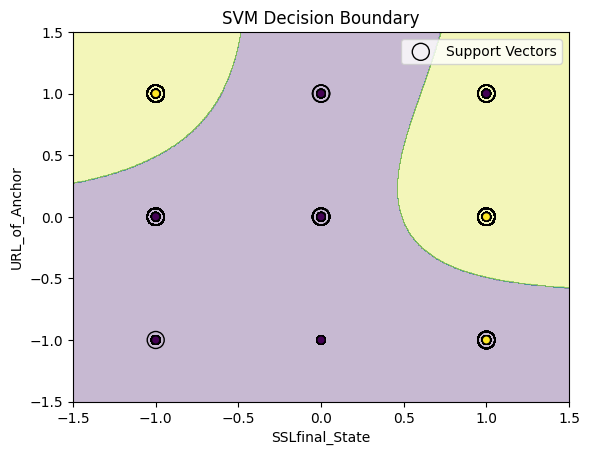

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split


x_graph = df[["SSLfinal_State", "URL_of_Anchor"]]
y_graph = df["Result"]


x_train_graph, x_test_graph, y_train_graph, y_test_graph = train_test_split(
    x_graph,
    y_graph,
    test_size=0.2,
    random_state=42
)


graph_model = SVC(kernel="rbf", C=1)

graph_model.fit(x_train_graph, y_train_graph)


x_min = x_graph.iloc[:, 0].min() - 0.5
x_max = x_graph.iloc[:, 0].max() + 0.5

y_min = x_graph.iloc[:, 1].min() - 0.5
y_max = x_graph.iloc[:, 1].max() + 0.5


xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)


grid = np.c_[xx.ravel(), yy.ravel()]

grid = pd.DataFrame(
    grid,
    columns=x_graph.columns
)


z = graph_model.predict(grid)

z = z.reshape(xx.shape)


plt.contourf(
    xx,
    yy,
    z,
    alpha=0.3
)


plt.scatter(
    x_train_graph.iloc[:, 0],
    x_train_graph.iloc[:, 1],
    c=y_train_graph,
    edgecolors="black"
)


plt.scatter(
    graph_model.support_vectors_[:, 0],
    graph_model.support_vectors_[:, 1],
    facecolors="none",
    edgecolors="black",
    s=150,
    label="Support Vectors"
)


plt.xlabel(x_graph.columns[0])
plt.ylabel(x_graph.columns[1])

plt.title("SVM Decision Boundary")

plt.legend()

plt.show()